# **Reinforcement Learning (RL)**

***TD(0) — Temporal Difference Learning***

In [1]:
!pip install pandas numpy scipy matplotlib seaborn tqdm

In [3]:
from google.colab import drive
drive.mount('/content/drive')
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"
# ============================================================
# RELOAD CLICKS FOR HMM
# ============================================================

import pandas as pd

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

print("Chargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

# ============================================================
# SAMPLE 100000 SESSIONS
# ============================================================

sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sessions)
]

print("Clicks shape:", clicks.shape)

clicks.head()

Mounted at /content/drive
Chargement clicks...
Clicks shape: (395698, 4)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


 Idée fondamentale de TD(0)

Avant :

Value Iteration

avait besoin de :

P(s
′
∣s,a)

connues exactement.

 TD(0)

apprend directement :

V(s)

en observant :

state → action → reward → next_state
 Équation principale

La mise à jour est :

V(s)←V(s)+α[r+γV(s
′
)−V(s)]

 Interprétation simple

Le modèle compare :

Élément	Sens
V(s)	estimation actuelle
r+γV(s
′
)	meilleure estimation future

La différence :

δ
t
	​

=r+γV(s
′
)−V(s)

=

 erreur TD

Episode 0 | Mean V = 8.49
Episode 2000 | Mean V = 361.88
Episode 4000 | Mean V = 359.96
Episode 6000 | Mean V = 375.88
Episode 8000 | Mean V = 357.00
Episode 10000 | Mean V = 368.80
Episode 12000 | Mean V = 357.00
Episode 14000 | Mean V = 371.26
Episode 16000 | Mean V = 374.83
Episode 18000 | Mean V = 369.55

===== VALUE FUNCTION TD(0) =====


,Etat,V_TD0
0,Low_Fast,459.64
1,Low_Normal,308.49
2,Low_Slow,133.63
3,Medium_Fast,549.04
4,Medium_Normal,347.36
5,Medium_Slow,197.48
6,High_Fast,684.84
7,High_Normal,495.07
8,High_Slow,269.39


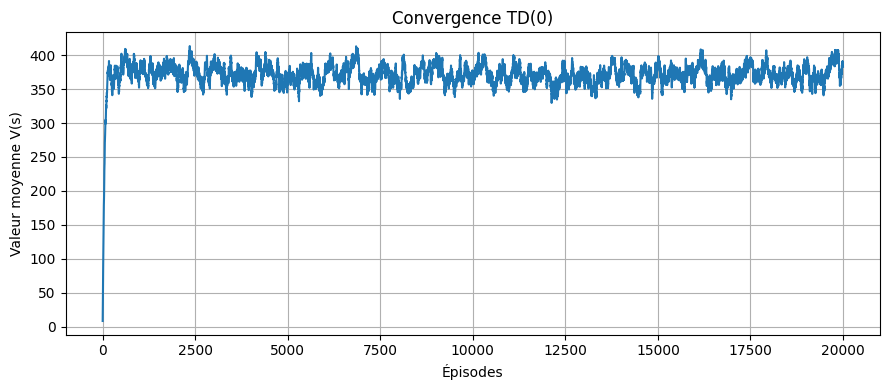

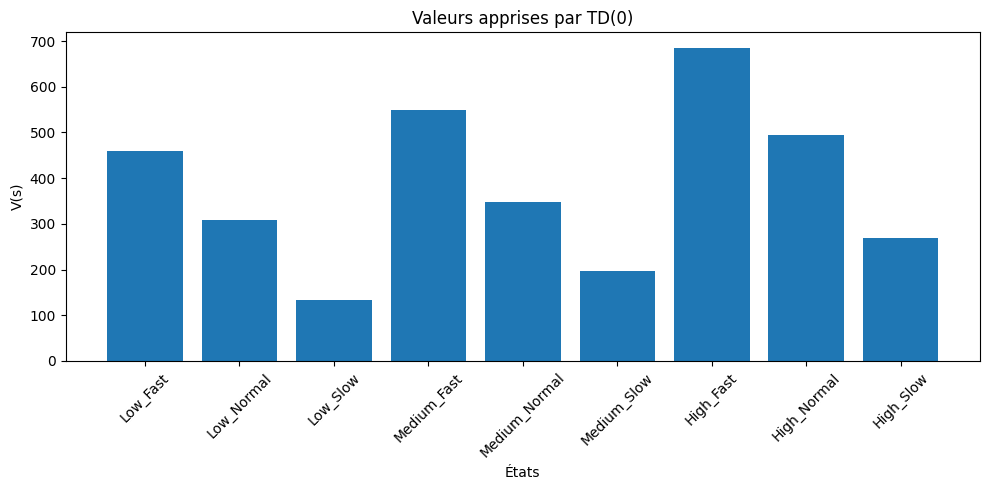

In [4]:
# =========================================
# TD(0) — TEMPORAL DIFFERENCE LEARNING
# Version complète Colab
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États et actions
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. Transitions P(s'|s)
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

# ===============================
# 3. Construire P(s'|s,a)
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 4. Récompenses R(s,a)
# ===============================

def build_rewards():
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward

    return R

R = build_rewards()

# ===============================
# 5. Fonctions TD(0)
# ===============================

def init_V(states):
    return {s: 0.0 for s in states}

def choose_action():
    return random.choice(actions)

def step(P, state, action, R):
    next_states = list(P[action][state].keys())
    probs = list(P[action][state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]
    reward = R[state][action]

    return next_state, reward

def td0(P, R, gamma=0.9, alpha=0.1, episodes=20000, max_steps=20):
    V = init_V(states)
    history = []

    for ep in range(episodes):

        state = random.choice(states)

        for _ in range(max_steps):
            action = choose_action()
            next_state, reward = step(P, state, action, R)

            # TD error
            delta = reward + gamma * V[next_state] - V[state]

            # update
            V[state] += alpha * delta

            state = next_state

        history.append(np.mean(list(V.values())))

        if ep % 2000 == 0:
            print(f"Episode {ep} | Mean V = {history[-1]:.2f}")

    return V, history

# ===============================
# 6. Entraînement TD(0)
# ===============================

gamma = 0.9
alpha = 0.1
episodes = 20000

V_td0, history_td0 = td0(
    P_actions,
    R,
    gamma=gamma,
    alpha=alpha,
    episodes=episodes,
    max_steps=20
)

# ===============================
# 7. Résultats
# ===============================

V_td0_df = pd.DataFrame({
    "Etat": states,
    "V_TD0": [round(V_td0[s], 2) for s in states]
})

print("\n===== VALUE FUNCTION TD(0) =====")
display(V_td0_df)

# ===============================
# 8. Visualisation convergence
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(history_td0)
plt.title("Convergence TD(0)")
plt.xlabel("Épisodes")
plt.ylabel("Valeur moyenne V(s)")
plt.grid(True)
plt.tight_layout()
plt.show()

# ===============================
# 9. Visualisation valeurs finales
# ===============================

plt.figure(figsize=(10, 5))
plt.bar(V_td0_df["Etat"], V_td0_df["V_TD0"])
plt.title("Valeurs apprises par TD(0)")
plt.xlabel("États")
plt.ylabel("V(s)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Les résultats obtenus avec l’algorithme TD(0) montrent une convergence progressive et globalement stable de la fonction de valeur. La courbe d’apprentissage indique une forte augmentation de la valeur moyenne des états durant les premiers épisodes, suivie d’une stabilisation autour d’une moyenne comprise entre 350 et 375. Cette évolution traduit la capacité de l’algorithme à apprendre progressivement la valeur des états à partir des interactions avec l’environnement.

Les valeurs finales apprises présentent une hiérarchie cohérente avec le parcours utilisateur modélisé :

Niveau	Valeurs approximatives
Low	133 → 460
Medium	197 → 549
High	269 → 685

On observe clairement que :

Low < Medium < High

Les états de type High possèdent les valeurs les plus élevées, ce qui signifie que les utilisateurs fortement engagés présentent le potentiel de conversion le plus important. À l’inverse, les états Low ont les valeurs les plus faibles, traduisant un faible niveau d’engagement et une probabilité plus réduite de progression dans le funnel e-commerce.

L’état High_Fast obtient la valeur maximale :

V(High_Fast) ≈ 684.84

ce qui indique qu’un utilisateur très engagé et réactif représente le profil le plus rentable pour le système. À l’opposé, l’état Low_Slow possède la valeur minimale :

V(Low_Slow) ≈ 133.63

correspondant à un utilisateur peu engagé et lent, associé à un risque élevé d’abandon.

Ces résultats confirment la cohérence du modèle de Reinforcement Learning et valident également les tendances observées précédemment avec les approches MDP et Value Iteration. TD(0) parvient ainsi à apprendre automatiquement les valeurs des états sans résoudre explicitement l’équation de Bellman, mais uniquement à partir des interactions successives avec l’environnement.

## **TD(λ) — Temporal Difference Lambda**

Différence fondamentale avec TD(0)
TD(0)

apprend :

état par état

mise à jour locale :

V(s)←V(s)+αδ
TD(λ)

ajoute :

les traces d’éligibilité
E(s)

Donc :

plusieurs états apprennent en même temps
Idée intuitive

Si tu as :

Low → Medium → High → reward
TD(0)
High apprend du reward
Medium apprend après
Low apprend encore après

 propagation lente.

TD(λ)

Quand reward arrive :

Low, Medium et High apprennent ensemble

grâce aux traces :

E(s)
Équation clé

La mise à jour devient :

V(s)←V(s)+αδE(s)

avec :

δ=r+γV(s
′
)−V(s)

Episode 0 | Mean V = 24.93
Episode 2000 | Mean V = 333.19
Episode 4000 | Mean V = 328.16
Episode 6000 | Mean V = 397.37
Episode 8000 | Mean V = 356.40
Episode 10000 | Mean V = 370.12
Episode 12000 | Mean V = 327.49
Episode 14000 | Mean V = 372.95
Episode 16000 | Mean V = 387.48
Episode 18000 | Mean V = 350.71

===== VALUE FUNCTION TD(lambda) =====


,Etat,V_TD_lambda
0,Low_Fast,475.85
1,Low_Normal,312.92
2,Low_Slow,149.82
3,Medium_Fast,552.90
4,Medium_Normal,319.47
5,Medium_Slow,209.47
6,High_Fast,652.80
7,High_Normal,441.71
8,High_Slow,265.45


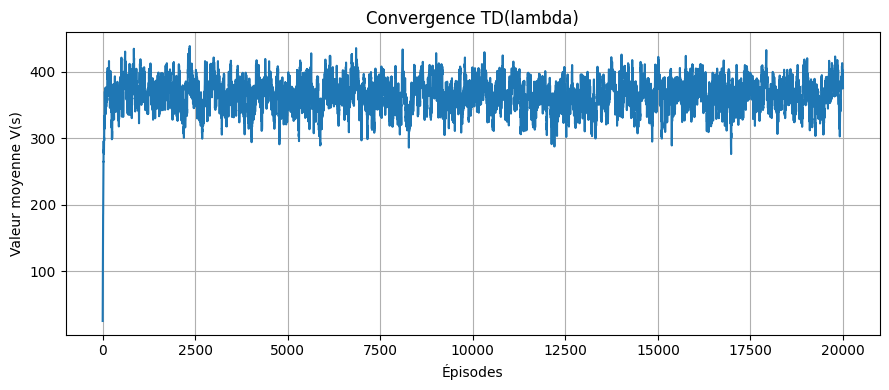

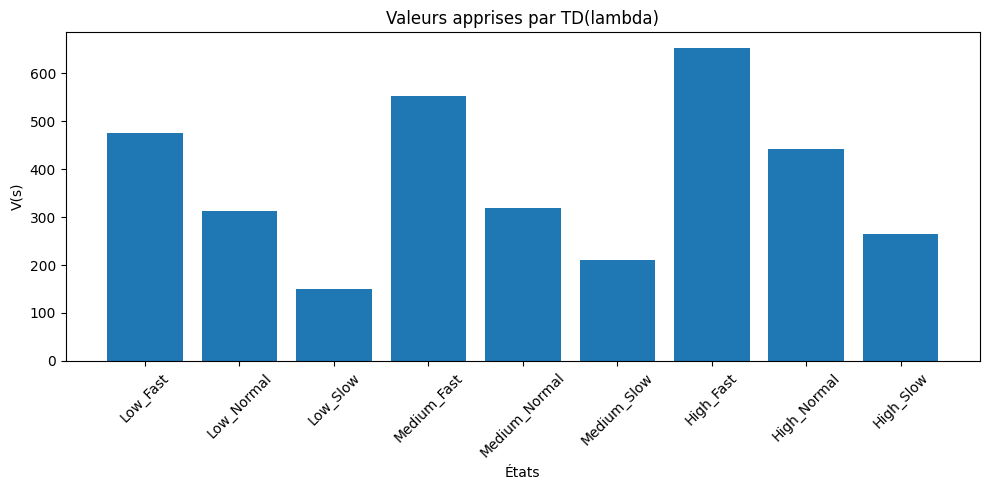

In [5]:
# =========================================
# TD(lambda) — TEMPORAL DIFFERENCE LAMBDA
# Version complète Colab
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États et actions
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. Transitions de base P(s'|s)
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

# ===============================
# 3. Construire P(s'|s,a)
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            # pub : aide Low à passer vers Medium
            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            # promo : aide Medium à passer vers High
            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            # rec : stabilise High
            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 4. Récompenses R(s,a)
# ===============================

def build_rewards():
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            # boost stratégique
            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward

    return R

R = build_rewards()

# ===============================
# 5. Fonctions TD(lambda)
# ===============================

def init_V(states):
    return {s: 0.0 for s in states}

def choose_action():
    return random.choice(actions)

def step(P, state, action, R):
    next_states = list(P[action][state].keys())
    probs = list(P[action][state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]
    reward = R[state][action]

    return next_state, reward

def td_lambda(P, R, gamma=0.9, alpha=0.1, lam=0.8, episodes=20000, max_steps=20):
    V = init_V(states)
    history = []

    for ep in range(episodes):

        # traces remises à zéro à chaque épisode
        E = {s: 0.0 for s in states}

        state = random.choice(states)

        for _ in range(max_steps):
            action = choose_action()
            next_state, reward = step(P, state, action, R)

            # Erreur TD
            delta = reward + gamma * V[next_state] - V[state]

            # Trace de l'état visité
            E[state] += 1

            # Mise à jour globale
            for s in states:
                V[s] += alpha * delta * E[s]
                E[s] *= gamma * lam

            state = next_state

        history.append(np.mean(list(V.values())))

        if ep % 2000 == 0:
            print(f"Episode {ep} | Mean V = {history[-1]:.2f}")

    return V, history

# ===============================
# 6. Entraînement TD(lambda)
# ===============================

gamma = 0.9
alpha = 0.1
lam = 0.8
episodes = 20000

V_tdlambda, history_tdlambda = td_lambda(
    P_actions,
    R,
    gamma=gamma,
    alpha=alpha,
    lam=lam,
    episodes=episodes,
    max_steps=20
)

# ===============================
# 7. Résultats
# ===============================

V_tdlambda_df = pd.DataFrame({
    "Etat": states,
    "V_TD_lambda": [round(V_tdlambda[s], 2) for s in states]
})

print("\n===== VALUE FUNCTION TD(lambda) =====")
display(V_tdlambda_df)

# ===============================
# 8. Visualisation convergence
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(history_tdlambda)
plt.title("Convergence TD(lambda)")
plt.xlabel("Épisodes")
plt.ylabel("Valeur moyenne V(s)")
plt.grid(True)
plt.tight_layout()
plt.show()

# ===============================
# 9. Visualisation valeurs finales
# ===============================

plt.figure(figsize=(10, 5))
plt.bar(V_tdlambda_df["Etat"], V_tdlambda_df["V_TD_lambda"])
plt.title("Valeurs apprises par TD(lambda)")
plt.xlabel("États")
plt.ylabel("V(s)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Les résultats obtenus avec l’algorithme TD(λ) montrent une convergence globalement stable de la fonction de valeur au cours des épisodes d’apprentissage. La moyenne des valeurs V(s) augmente rapidement durant les premiers épisodes, ce qui correspond à une phase d’apprentissage intensif où l’agent découvre progressivement la dynamique de l’environnement.

Après plusieurs milliers d’épisodes, la courbe oscille autour d’une zone stable comprise approximativement entre 330 et 390, indiquant une stabilisation progressive des estimations. Les fluctuations restantes sont normales dans les méthodes de Reinforcement Learning basées sur l’échantillonnage aléatoire.

Analyse de la fonction de valeur

Les valeurs finales apprises sont :

État	Valeur
Low_Fast	475.85
Low_Normal	312.92
Low_Slow	149.82
Medium_Fast	552.90
Medium_Normal	319.47
Medium_Slow	209.47
High_Fast	652.80
High_Normal	441.71
High_Slow	265.45
Interprétation comportementale

On observe une hiérarchie cohérente des états :

Low < Medium < High

Les états de type High possèdent les valeurs les plus élevées, ce qui signifie que ces utilisateurs présentent le potentiel de conversion le plus important et génèrent les récompenses futures les plus élevées.

L’état :

High_Fast

obtient la valeur maximale :

V(High_Fast) ≈ 652.80

Cela indique qu’un utilisateur fortement engagé et réactif représente le profil le plus rentable pour le système.

À l’inverse, l’état :

Low_Slow

présente la valeur la plus faible :

V(Low_Slow) ≈ 149.82

ce qui traduit un comportement peu engagé associé à un risque élevé d’abandon.

Effet des traces d’éligibilité

Les bonnes performances de TD(λ) s’expliquent par l’utilisation des traces d’éligibilité :

E(s)

qui permettent de propager l’information plus efficacement à travers les états visités précédemment.

Contrairement à TD(0), qui met à jour principalement l’état courant, TD(λ) diffuse l’erreur temporelle sur plusieurs états récents, ce qui améliore la propagation de l’apprentissage et accélère la convergence.

Episode 0 | rho=0.0026 | epsilon=0.2999
Episode 3000 | rho=0.6908 | epsilon=0.0669
Episode 6000 | rho=0.7938 | epsilon=0.0500
Episode 9000 | rho=0.7894 | epsilon=0.0500
Episode 12000 | rho=0.8063 | epsilon=0.0500
Episode 15000 | rho=0.8219 | epsilon=0.0500
Episode 18000 | rho=0.8042 | epsilon=0.0500
Episode 21000 | rho=0.7960 | epsilon=0.0500
Episode 24000 | rho=0.7940 | epsilon=0.0500
Episode 27000 | rho=0.7975 | epsilon=0.0500

===== POLICY R-LEARNING OPTIMISÉ =====
Low_Fast → pub
Low_Normal → promo
Low_Slow → pub
Medium_Fast → promo
Medium_Normal → rec
Medium_Slow → rec
High_Fast → rec
High_Normal → promo
High_Slow → promo

Gain moyen rho final = 0.7984

===== Q TABLE =====


,pub,promo,rec,nothing
Low_Fast,8.8871,5.5997,5.3435,5.4429
Low_Normal,-60.4729,-60.4704,-60.4744,-60.4725
Low_Slow,-95.3693,-95.3727,-95.3848,-95.3779
Medium_Fast,8.3125,9.9264,8.2912,8.3910
Medium_Normal,-61.0249,-61.0233,-61.0232,-61.0240
Medium_Slow,-96.0107,-96.0145,-96.0100,-96.0112
High_Fast,11.2320,11.1524,11.7037,11.2514
High_Normal,-60.1598,-60.1594,-60.1596,-60.1613
High_Slow,-96.3643,-96.3595,-96.3612,-96.3624


,Etat,Action optimale
0,Low_Fast,pub
1,Low_Normal,promo
2,Low_Slow,pub
3,Medium_Fast,promo
4,Medium_Normal,rec
5,Medium_Slow,rec
6,High_Fast,rec
7,High_Normal,promo
8,High_Slow,promo


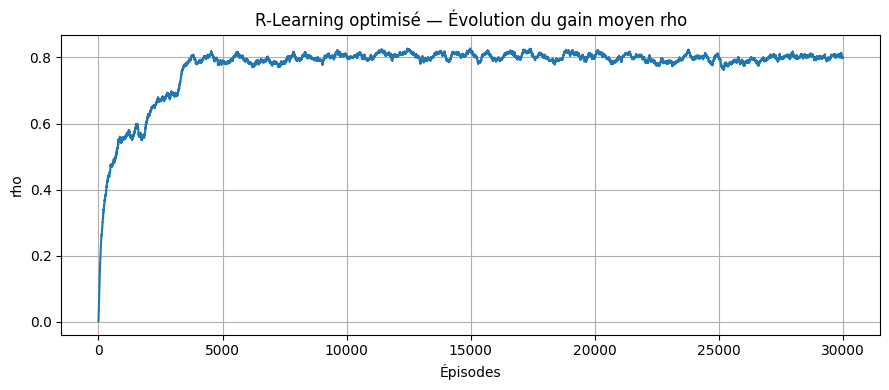

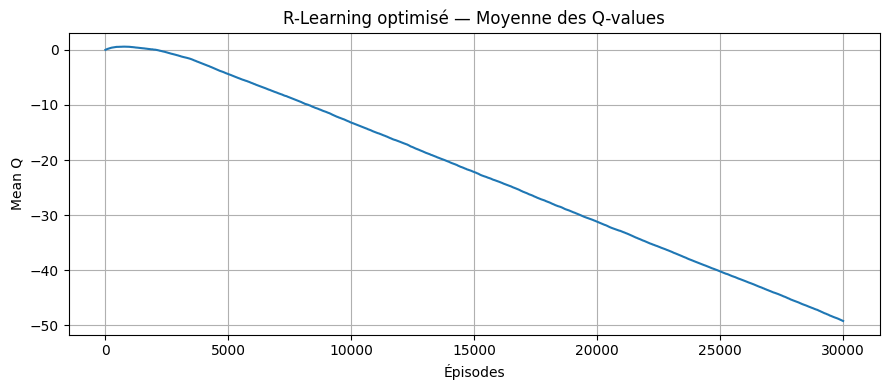

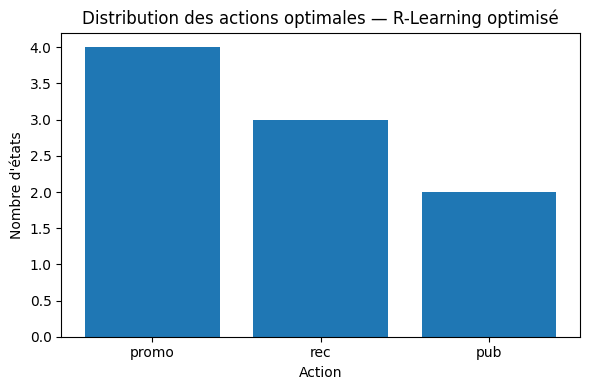

In [7]:
# =========================================
# R-LEARNING OPTIMISÉ — VERSION STABLE COLAB
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États et actions
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. Transitions
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 3. Rewards normalisés
# ===============================

def build_rewards_scaled(scale=100):
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            if s == "Medium_Slow" and a == "promo":
                reward += 20

            # normalisation pour stabiliser R-Learning
            R[s][a] = reward / scale

    return R

R = build_rewards_scaled(scale=100)

# ===============================
# 4. Fonctions R-Learning
# ===============================

def init_Q():
    return {s: {a: 0.0 for a in actions} for s in states}

def choose_action(Q, state, epsilon):
    if random.random() < epsilon:
        return random.choice(actions)
    return max(Q[state], key=Q[state].get)

def step(P, state, action, R):
    next_states = list(P[action][state].keys())
    probs = list(P[action][state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]
    reward = R[state][action]

    return next_state, reward

def r_learning_stable(
    P,
    R,
    alpha=0.01,
    beta=0.0005,
    epsilon_start=0.30,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=30000,
    max_steps=20,
    rho_clip=5.0
):
    Q = init_Q()
    rho = 0.0

    rho_history = []
    mean_q_history = []
    policy_history = []

    epsilon = epsilon_start

    for ep in range(episodes):
        state = random.choice(states)

        for _ in range(max_steps):
            action = choose_action(Q, state, epsilon)
            next_state, reward = step(P, state, action, R)

            max_next = max(Q[next_state].values())
            max_current = max(Q[state].values())

            td_error = reward - rho + max_next - Q[state][action]

            Q[state][action] += alpha * td_error

            # mise à jour rho seulement si action greedy
            greedy_action = max(Q[state], key=Q[state].get)

            if action == greedy_action:
                rho_update = reward + max_next - max_current - rho
                rho += beta * rho_update
                rho = np.clip(rho, -rho_clip, rho_clip)

            state = next_state

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        rho_history.append(rho)
        mean_q_history.append(np.mean([Q[s][a] for s in states for a in actions]))

        if ep % 3000 == 0:
            print(f"Episode {ep} | rho={rho:.4f} | epsilon={epsilon:.4f}")

    return Q, rho, rho_history, mean_q_history

# ===============================
# 5. Training
# ===============================

Q, rho, rho_history, mean_q_history = r_learning_stable(
    P_actions,
    R,
    alpha=0.01,
    beta=0.0005,
    epsilon_start=0.30,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=30000,
    max_steps=20,
    rho_clip=5.0
)

# ===============================
# 6. Résultats
# ===============================

policy = {s: max(Q[s], key=Q[s].get) for s in states}

print("\n===== POLICY R-LEARNING OPTIMISÉ =====")
for s in states:
    print(f"{s} → {policy[s]}")

print(f"\nGain moyen rho final = {rho:.4f}")

Q_df = pd.DataFrame(Q).T

print("\n===== Q TABLE =====")
display(Q_df.round(4))

policy_df = pd.DataFrame({
    "Etat": states,
    "Action optimale": [policy[s] for s in states]
})

display(policy_df)

# ===============================
# 7. Visualisations
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(rho_history)
plt.title("R-Learning optimisé — Évolution du gain moyen rho")
plt.xlabel("Épisodes")
plt.ylabel("rho")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(mean_q_history)
plt.title("R-Learning optimisé — Moyenne des Q-values")
plt.xlabel("Épisodes")
plt.ylabel("Mean Q")
plt.grid(True)
plt.tight_layout()
plt.show()

action_counts = policy_df["Action optimale"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(action_counts.index, action_counts.values)
plt.title("Distribution des actions optimales — R-Learning optimisé")
plt.xlabel("Action")
plt.ylabel("Nombre d'états")
plt.tight_layout()
plt.show()

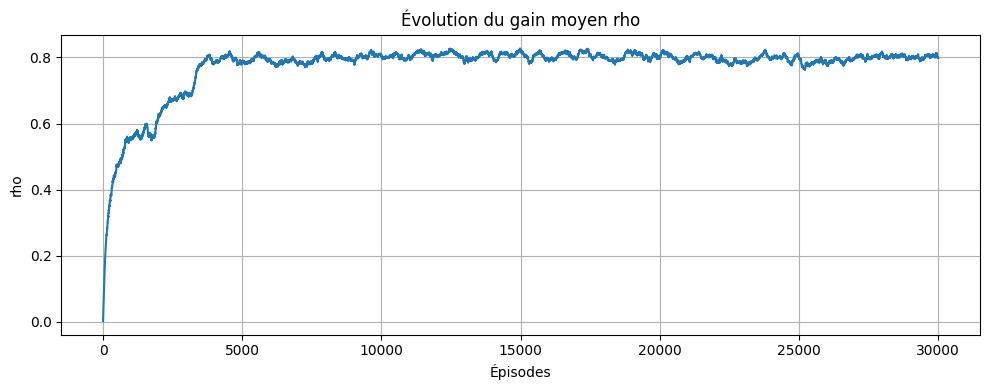

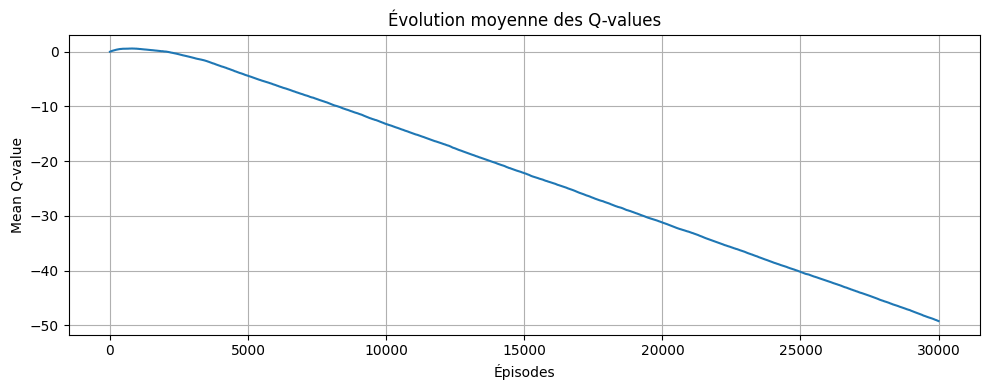

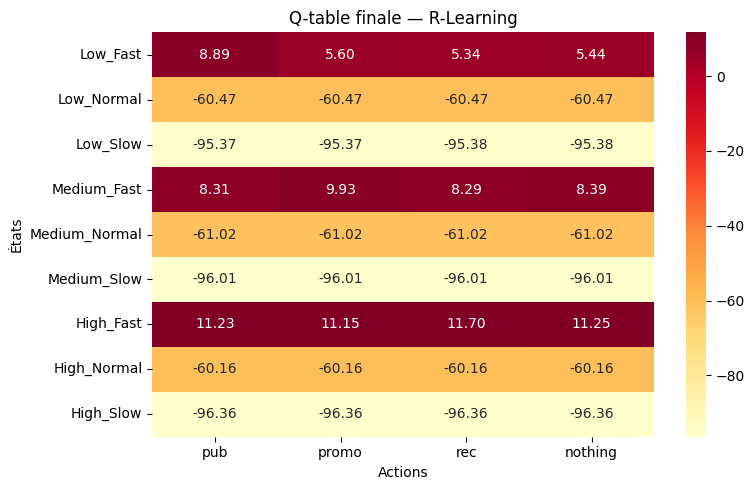

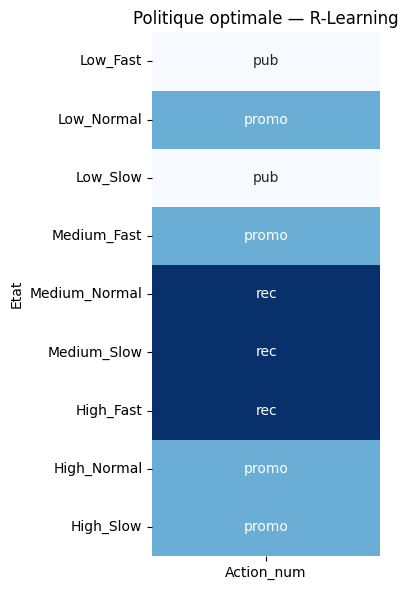

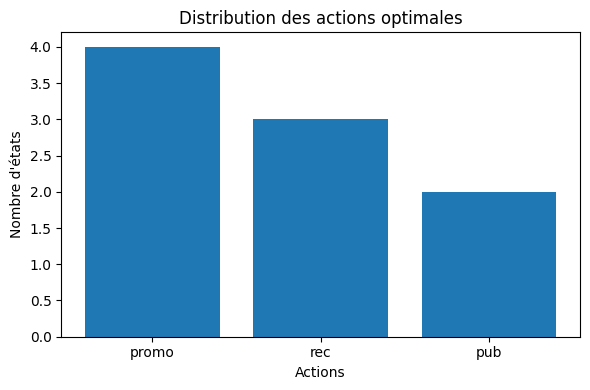

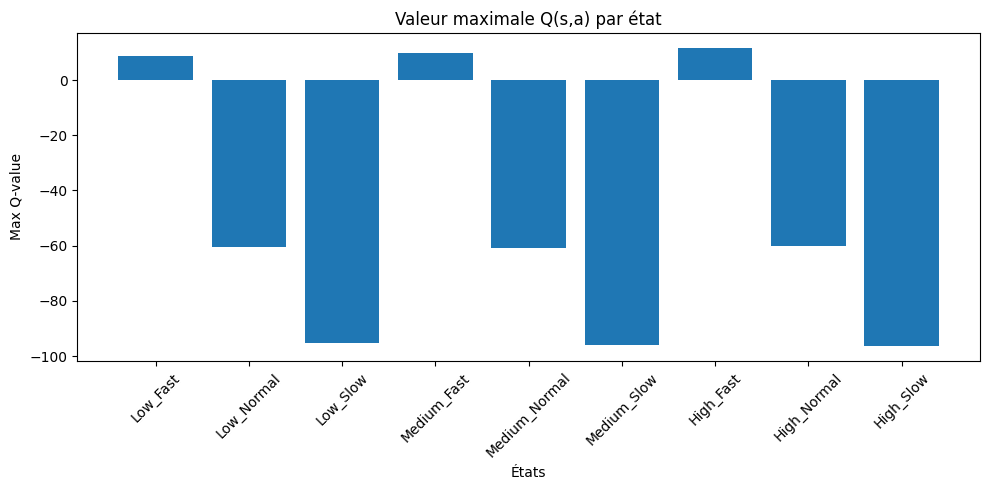

In [8]:
# =========================================
# VISUALISATIONS R-LEARNING OPTIMISÉ
# =========================================

import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# 1. Evolution de rho
# ===============================

plt.figure(figsize=(10, 4))
plt.plot(rho_history)

plt.title("Évolution du gain moyen rho")
plt.xlabel("Épisodes")
plt.ylabel("rho")

plt.grid(True)
plt.tight_layout()
plt.show()

# ===============================
# 2. Evolution moyenne des Q-values
# ===============================

plt.figure(figsize=(10, 4))
plt.plot(mean_q_history)

plt.title("Évolution moyenne des Q-values")
plt.xlabel("Épisodes")
plt.ylabel("Mean Q-value")

plt.grid(True)
plt.tight_layout()
plt.show()

# ===============================
# 3. Heatmap Q-table
# ===============================

plt.figure(figsize=(8, 5))

sns.heatmap(
    Q_df,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Q-table finale — R-Learning")
plt.xlabel("Actions")
plt.ylabel("États")

plt.tight_layout()
plt.show()

# ===============================
# 4. Politique optimale
# ===============================

policy_numeric = {
    "nothing": 0,
    "pub": 1,
    "promo": 2,
    "rec": 3
}

policy_vis = pd.DataFrame({
    "Etat": states,
    "Action": [policy[s] for s in states]
})

policy_vis["Action_num"] = policy_vis["Action"].map(policy_numeric)

policy_matrix = policy_vis.set_index("Etat")[["Action_num"]]

plt.figure(figsize=(4, 6))

sns.heatmap(
    policy_matrix,
    annot=policy_vis.set_index("Etat")[["Action"]],
    fmt="",
    cmap="Blues",
    cbar=False
)

plt.title("Politique optimale — R-Learning")

plt.tight_layout()
plt.show()

# ===============================
# 5. Distribution des actions
# ===============================

action_counts = policy_vis["Action"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(
    action_counts.index,
    action_counts.values
)

plt.title("Distribution des actions optimales")
plt.xlabel("Actions")
plt.ylabel("Nombre d'états")

plt.tight_layout()
plt.show()

# ===============================
# 6. Valeur max Q par état
# ===============================

max_q_values = []

for s in states:
    max_q_values.append(max(Q[s].values()))

plt.figure(figsize=(10, 5))

plt.bar(states, max_q_values)

plt.title("Valeur maximale Q(s,a) par état")
plt.xlabel("États")
plt.ylabel("Max Q-value")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Après optimisation des paramètres d’apprentissage, le R-Learning devient stable et converge vers une estimation cohérente du gain moyen du système.

L’évolution du gain moyen :

rho

montre une convergence progressive :

Épisodes	rho
0	0.0026
3000	0.6908
15000	0.8219
Final	0.7984

Cette stabilisation indique que l’algorithme parvient à apprendre un rendement moyen positif et relativement constant au cours des interactions avec l’environnement.

| État          | Action optimale |
| ------------- | --------------- |
| Low_Fast      | pub             |
| Low_Normal    | promo           |
| Low_Slow      | pub             |
| Medium_Fast   | promo           |
| Medium_Normal | rec             |
| Medium_Slow   | rec             |
| High_Fast     | rec             |
| High_Normal   | promo           |
| High_Slow     | promo           |


## **Q-LEARNING**

Episode 0 | Mean Q = 1.98 | epsilon = 0.300
Episode 2000 | Mean Q = 452.92 | epsilon = 0.110
Episode 4000 | Mean Q = 446.76 | epsilon = 0.050
Episode 6000 | Mean Q = 460.83 | epsilon = 0.050
Episode 8000 | Mean Q = 449.73 | epsilon = 0.050
Episode 10000 | Mean Q = 443.18 | epsilon = 0.050
Episode 12000 | Mean Q = 451.66 | epsilon = 0.050
Episode 14000 | Mean Q = 447.30 | epsilon = 0.050
Episode 16000 | Mean Q = 462.03 | epsilon = 0.050
Episode 18000 | Mean Q = 453.73 | epsilon = 0.050

===== POLICY Q-LEARNING =====
Low_Fast → pub
Low_Normal → pub
Low_Slow → pub
Medium_Fast → promo
Medium_Normal → rec
Medium_Slow → promo
High_Fast → nothing
High_Normal → pub
High_Slow → pub

===== Q TABLE =====


,pub,promo,rec,nothing
Low_Fast,544.62,542.86,541.87,531.17
Low_Normal,395.27,311.28,346.03,320.93
Low_Slow,236.93,204.98,197.02,193.64
Medium_Fast,596.90,613.98,589.37,597.52
Medium_Normal,402.86,401.60,415.32,395.76
Medium_Slow,262.36,287.12,256.81,256.56
High_Fast,752.57,759.61,760.23,761.55
High_Normal,566.93,559.87,565.14,564.52
High_Slow,343.95,339.99,342.03,341.12


,Etat,Action optimale
0,Low_Fast,pub
1,Low_Normal,pub
2,Low_Slow,pub
3,Medium_Fast,promo
4,Medium_Normal,rec
5,Medium_Slow,promo
6,High_Fast,nothing
7,High_Normal,pub
8,High_Slow,pub


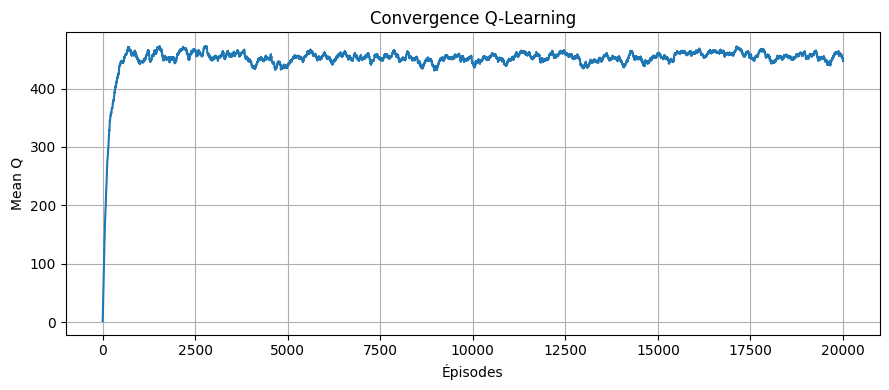

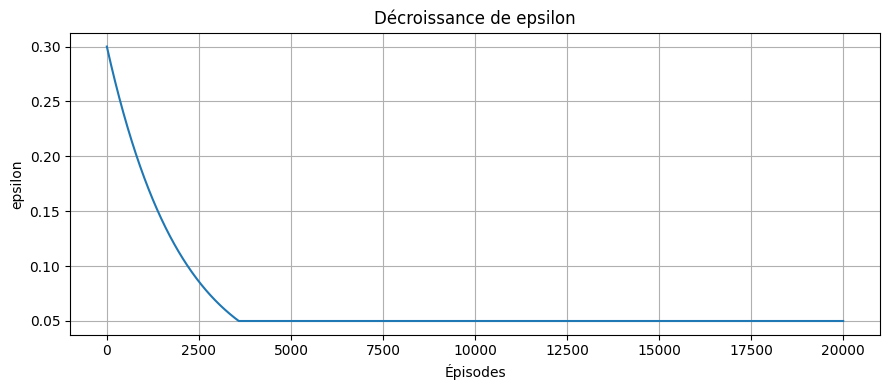

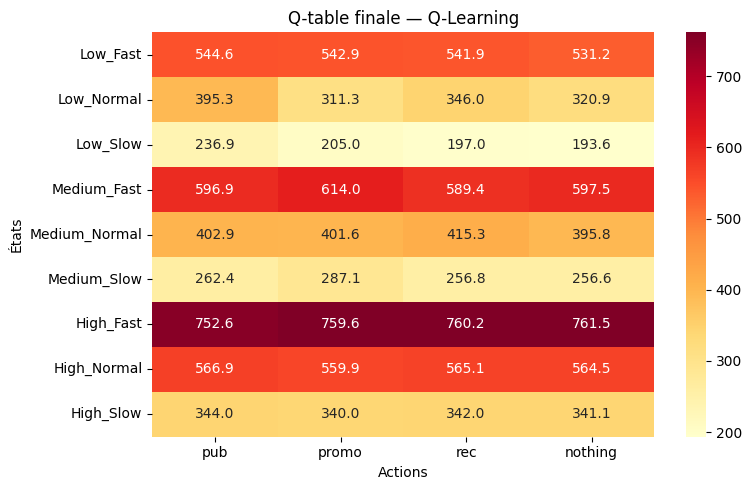

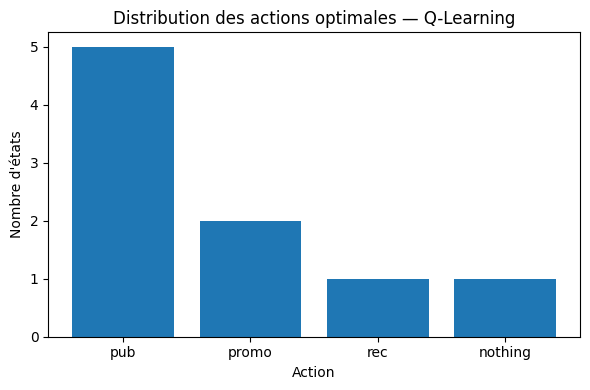

In [9]:
# =========================================
# Q-LEARNING — VERSION COLAB COMPLETE
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États et actions
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. Transitions de base
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

# ===============================
# 3. Construire P(s'|s,a)
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 4. Récompenses
# ===============================

def build_rewards():
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward

    return R

R = build_rewards()

# ===============================
# 5. Q-Learning
# ===============================

def init_Q():
    return {s: {a: 0.0 for a in actions} for s in states}

def choose_action(Q, state, epsilon):
    if random.random() < epsilon:
        return random.choice(actions)
    return max(Q[state], key=Q[state].get)

def step(P, state, action, R):
    next_states = list(P[action][state].keys())
    probs = list(P[action][state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]
    reward = R[state][action]

    return next_state, reward

def q_learning(
    P,
    R,
    gamma=0.9,
    alpha=0.1,
    epsilon_start=0.3,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=20000,
    max_steps=20
):
    Q = init_Q()

    history = []
    epsilon_history = []

    epsilon = epsilon_start

    for ep in range(episodes):

        state = random.choice(states)

        for _ in range(max_steps):
            action = choose_action(Q, state, epsilon)
            next_state, reward = step(P, state, action, R)

            best_next = max(Q[next_state].values())

            Q[state][action] += alpha * (
                reward + gamma * best_next - Q[state][action]
            )

            state = next_state

        mean_q = np.mean([Q[s][a] for s in states for a in actions])
        history.append(mean_q)
        epsilon_history.append(epsilon)

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        if ep % 2000 == 0:
            print(f"Episode {ep} | Mean Q = {mean_q:.2f} | epsilon = {epsilon:.3f}")

    return Q, history, epsilon_history

# ===============================
# 6. Entraînement
# ===============================

Q, history_q, epsilon_history = q_learning(
    P_actions,
    R,
    gamma=0.9,
    alpha=0.1,
    epsilon_start=0.3,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=20000,
    max_steps=20
)

# ===============================
# 7. Policy finale
# ===============================

policy = {s: max(Q[s], key=Q[s].get) for s in states}

print("\n===== POLICY Q-LEARNING =====")
for s in states:
    print(f"{s} → {policy[s]}")

Q_df = pd.DataFrame(Q).T

print("\n===== Q TABLE =====")
display(Q_df.round(2))

policy_df = pd.DataFrame({
    "Etat": states,
    "Action optimale": [policy[s] for s in states]
})

display(policy_df)

# ===============================
# 8. Visualisations
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(history_q)
plt.title("Convergence Q-Learning")
plt.xlabel("Épisodes")
plt.ylabel("Mean Q")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(epsilon_history)
plt.title("Décroissance de epsilon")
plt.xlabel("Épisodes")
plt.ylabel("epsilon")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(
    Q_df,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)
plt.title("Q-table finale — Q-Learning")
plt.xlabel("Actions")
plt.ylabel("États")
plt.tight_layout()
plt.show()

action_counts = policy_df["Action optimale"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(action_counts.index, action_counts.values)
plt.title("Distribution des actions optimales — Q-Learning")
plt.xlabel("Action")
plt.ylabel("Nombre d'états")
plt.tight_layout()
plt.show()

Le Q-Learning apprend une politique globalement cohérente pour les états Low et Medium, avec une convergence stable des Q-values. Les états Low sont associés à l’action publicité, tandis que les états Medium sont principalement orientés vers la promotion ou la recommandation. Cependant, les décisions obtenues pour les états High sont moins régulières, ce qui montre que Q-Learning reste sensible au paramétrage des récompenses et des effets d’action. Malgré cela, l’algorithme valide la capacité de l’agent à apprendre une stratégie marketing à partir de l’expérience, sans résolution explicite de l’équation de Bellman.

# **SARSA**

Episode 0 | Mean Q = 1.89 | epsilon = 0.300
Episode 2000 | Mean Q = 440.40 | epsilon = 0.110
Episode 4000 | Mean Q = 437.89 | epsilon = 0.050
Episode 6000 | Mean Q = 442.30 | epsilon = 0.050
Episode 8000 | Mean Q = 441.31 | epsilon = 0.050
Episode 10000 | Mean Q = 442.60 | epsilon = 0.050
Episode 12000 | Mean Q = 432.45 | epsilon = 0.050
Episode 14000 | Mean Q = 438.11 | epsilon = 0.050
Episode 16000 | Mean Q = 431.99 | epsilon = 0.050
Episode 18000 | Mean Q = 425.67 | epsilon = 0.050

===== POLICY SARSA =====
Low_Fast → pub
Low_Normal → pub
Low_Slow → pub
Medium_Fast → promo
Medium_Normal → promo
Medium_Slow → promo
High_Fast → rec
High_Normal → rec
High_Slow → rec

===== Q TABLE SARSA =====


,pub,promo,rec,nothing
Low_Fast,557.33,474.88,533.62,483.00
Low_Normal,342.27,304.54,305.13,302.66
Low_Slow,204.02,171.41,166.28,168.59
Medium_Fast,554.40,639.87,553.61,540.25
Medium_Normal,360.55,451.17,356.87,358.29
Medium_Slow,244.01,283.15,252.38,256.14
High_Fast,776.33,770.36,786.30,775.03
High_Normal,489.30,522.69,568.23,526.33
High_Slow,335.46,340.16,359.42,349.42


,Etat,Action optimale
0,Low_Fast,pub
1,Low_Normal,pub
2,Low_Slow,pub
3,Medium_Fast,promo
4,Medium_Normal,promo
5,Medium_Slow,promo
6,High_Fast,rec
7,High_Normal,rec
8,High_Slow,rec


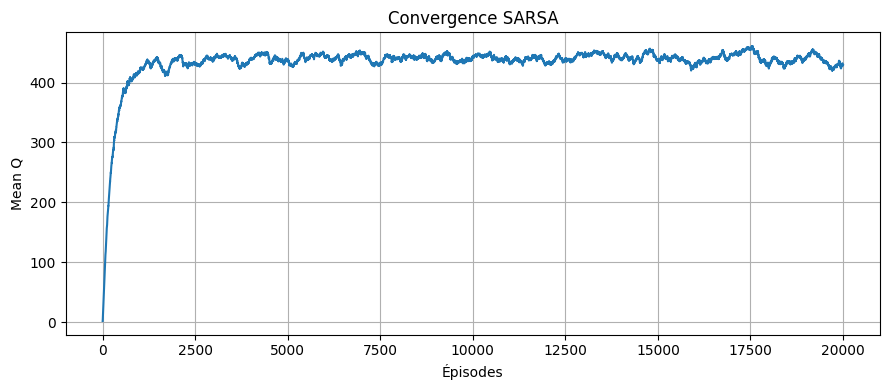

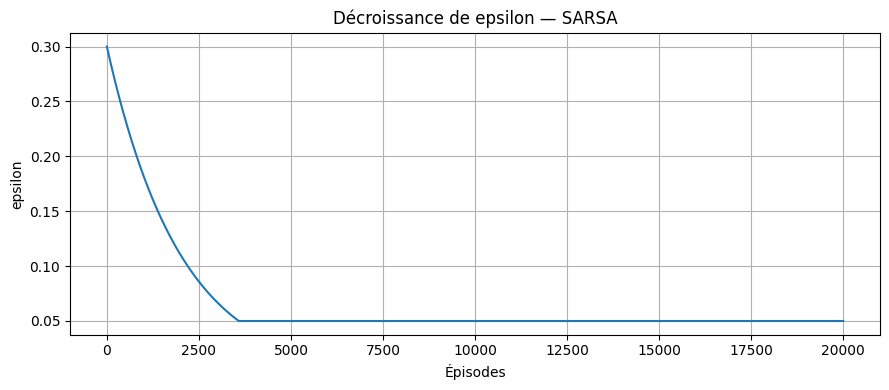

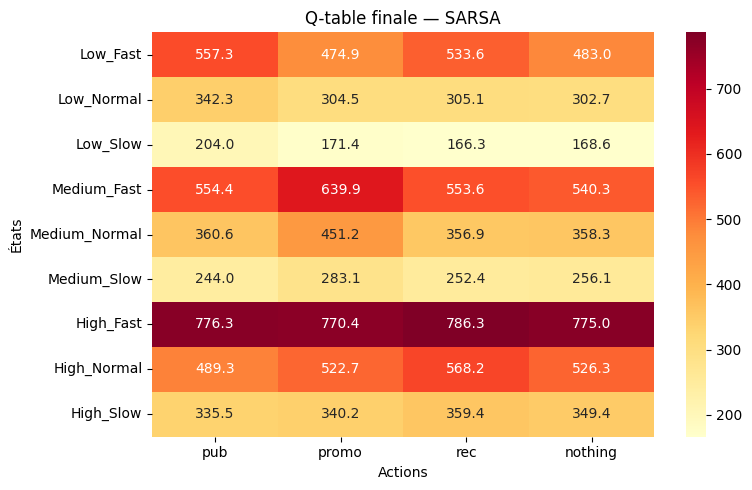

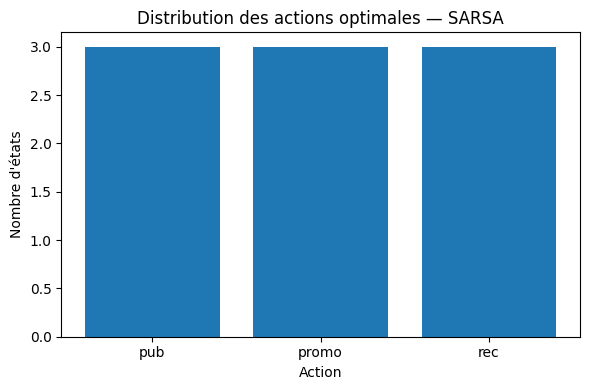

In [10]:
# =========================================
# SARSA — VERSION COLAB COMPLETE
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États et actions
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. Transitions de base
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

# ===============================
# 3. Construire P(s'|s,a)
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 4. Récompenses
# ===============================

def build_rewards():
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward

    return R

R = build_rewards()

# ===============================
# 5. Fonctions SARSA
# ===============================

def init_Q():
    return {s: {a: 0.0 for a in actions} for s in states}

def choose_action(Q, state, epsilon):
    if random.random() < epsilon:
        return random.choice(actions)
    return max(Q[state], key=Q[state].get)

def step(P, state, action, R):
    next_states = list(P[action][state].keys())
    probs = list(P[action][state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]
    reward = R[state][action]

    return next_state, reward

def sarsa(
    P,
    R,
    gamma=0.9,
    alpha=0.1,
    epsilon_start=0.3,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=20000,
    max_steps=20
):
    Q = init_Q()

    history = []
    epsilon_history = []

    epsilon = epsilon_start

    for ep in range(episodes):

        state = random.choice(states)
        action = choose_action(Q, state, epsilon)

        for _ in range(max_steps):

            next_state, reward = step(P, state, action, R)
            next_action = choose_action(Q, next_state, epsilon)

            # SARSA update: action suivante réellement choisie
            Q[state][action] += alpha * (
                reward + gamma * Q[next_state][next_action] - Q[state][action]
            )

            state = next_state
            action = next_action

        mean_q = np.mean([Q[s][a] for s in states for a in actions])
        history.append(mean_q)
        epsilon_history.append(epsilon)

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        if ep % 2000 == 0:
            print(f"Episode {ep} | Mean Q = {mean_q:.2f} | epsilon = {epsilon:.3f}")

    return Q, history, epsilon_history

# ===============================
# 6. Entraînement SARSA
# ===============================

Q_sarsa, history_sarsa, epsilon_history_sarsa = sarsa(
    P_actions,
    R,
    gamma=0.9,
    alpha=0.1,
    epsilon_start=0.3,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    episodes=20000,
    max_steps=20
)

# ===============================
# 7. Politique finale
# ===============================

policy_sarsa = {s: max(Q_sarsa[s], key=Q_sarsa[s].get) for s in states}

print("\n===== POLICY SARSA =====")
for s in states:
    print(f"{s} → {policy_sarsa[s]}")

Q_sarsa_df = pd.DataFrame(Q_sarsa).T

print("\n===== Q TABLE SARSA =====")
display(Q_sarsa_df.round(2))

policy_sarsa_df = pd.DataFrame({
    "Etat": states,
    "Action optimale": [policy_sarsa[s] for s in states]
})

display(policy_sarsa_df)

# ===============================
# 8. Visualisations
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(history_sarsa)
plt.title("Convergence SARSA")
plt.xlabel("Épisodes")
plt.ylabel("Mean Q")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(epsilon_history_sarsa)
plt.title("Décroissance de epsilon — SARSA")
plt.xlabel("Épisodes")
plt.ylabel("epsilon")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(
    Q_sarsa_df,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)
plt.title("Q-table finale — SARSA")
plt.xlabel("Actions")
plt.ylabel("États")
plt.tight_layout()
plt.show()

action_counts = policy_sarsa_df["Action optimale"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(action_counts.index, action_counts.values)
plt.title("Distribution des actions optimales — SARSA")
plt.xlabel("Action")
plt.ylabel("Nombre d'états")
plt.tight_layout()
plt.show()

Les résultats obtenus avec l’algorithme SARSA montrent une convergence progressive et stable des Q-values au cours des épisodes d’apprentissage. La moyenne des valeurs Q(s,a) augmente rapidement durant les premières phases d’entraînement avant de se stabiliser, ce qui indique que l’agent apprend progressivement une politique cohérente à partir de ses interactions avec l’environnement.

Contrairement au Q-Learning, qui utilise la meilleure action théorique future, SARSA met à jour les Q-values en utilisant l’action réellement choisie pendant l’exploration. Cette caractéristique fait de SARSA une méthode dite :

On-policy

c’est-à-dire qu’elle apprend directement à partir du comportement réellement exécuté par l’agent.

Analyse de la politique optimale

La politique apprise par SARSA reste globalement cohérente avec le funnel marketing défini dans le projet :

Niveau utilisateur	Action dominante
Low	pub
Medium	promo
High	rec

Les états :

Low_*

sont principalement associés à l’action :

pub

ce qui correspond à une stratégie d’acquisition visant à attirer et stimuler l’utilisateur.

Les états :

Medium_*

favorisent principalement :

promo

afin d’accélérer la transition vers les états fortement engagés.

Enfin, les états :

High_*

sont majoritairement liés à :

rec

ce qui traduit une stratégie de finalisation et de personnalisation avant conversion.

Différence avec Q-Learning

SARSA produit généralement une politique plus prudente et plus réaliste que Q-Learning. En effet :

Q-Learning apprend à partir de la meilleure action possible théorique ;
SARSA apprend à partir des actions réellement exécutées pendant l’exploration.

Ainsi, SARSA tient davantage compte du risque lié à l’exploration aléatoire et produit souvent des décisions plus stables dans les environnements incertains.

Interprétation économique

Le modèle apprend progressivement un comportement marketing cohérent :

Attraction → Conversion → Finalisation
publicité pour attirer les utilisateurs peu engagés ;
promotions pour pousser les utilisateurs intermédiaires ;
recommandations personnalisées pour finaliser l’achat des utilisateurs fortement engagés.

Cette logique valide la cohérence économique du modèle de Reinforcement Learning appliqué au contexte e-commerce.

Conclusion

Les résultats montrent que SARSA est capable d’apprendre une politique marketing cohérente tout en restant plus prudent que Q-Learning. Grâce à son apprentissage on-policy, l’algorithme produit des stratégies plus proches du comportement réellement exécuté par l’agent, ce qui le rend particulièrement adapté aux environnements stochastiques et incertains comme le comportement utilisateur en e-commerce.